<a href="https://colab.research.google.com/github/sahanyafernando/Intelligent-Driver-Monitoring-Assistant-/blob/main/02_Nexar_Metadata_Analysis_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadRisk AI - Nexar Collision Prediction Metadata Analysis

**Purpose:** Analyse the Nexar train metadata before doing any expensive video training.

Official dataset page: https://huggingface.co/datasets/nexar-ai/nexar_collision_prediction  
Kaggle challenge: https://www.kaggle.com/competitions/nexar-collision-prediction

We only use the **metadata CSV** for these proposal graphs.

The official dataset treats **collision and near-miss clips together as positive cases**, so do not claim the target column separates those two event types unless your copy contains an additional verified label.

## 1. Setup

In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

OUTPUT_DIR='/content/roadrisk_nexar_figures'
os.makedirs(OUTPUT_DIR, exist_ok=True)
plt.rcParams['figure.figsize']=(8.5,5.5)
plt.rcParams['axes.grid']=True
plt.rcParams['grid.alpha']=0.2


## 2. Upload `train.csv` or a metadata CSV

Different distributions of the dataset may use `target` or `label`. The code below detects either.

In [2]:
print('Upload Nexar train.csv / metadata CSV now...')
uploaded=files.upload()
filename=next(iter(uploaded))

df=pd.read_csv(filename)
df.columns=[str(c).strip() for c in df.columns]
print('Shape:',df.shape)
display(df.head())
print('Columns:',list(df.columns))


Upload Nexar train.csv / metadata CSV now...


Saving train.csv to train.csv
Shape: (1500, 4)


,id,time_of_event,time_of_alert,target
0,1924,NaN,NaN,0
1,822,19.5,18.633,1
2,1429,NaN,NaN,0
3,208,19.8,19.233,1
4,1904,NaN,NaN,0


Columns: ['id', 'time_of_event', 'time_of_alert', 'target']


In [3]:
# Standardise common column names without modifying the original file on disk.
work=df.copy()

label_col=None
for c in ['target','label','class','y']:
    if c in work.columns:
        label_col=c
        break

# Some metadata exports infer positives from a non-null event time.
if label_col is None and 'time_of_event' in work.columns:
    work['_derived_label']=work['time_of_event'].notna().astype(int)
    label_col='_derived_label'
    print('No explicit label/target column found; derived label from non-null time_of_event.')

print('Using label column:', label_col)


Using label column: target


### Figure 4 - Positive vs normal clip distribution

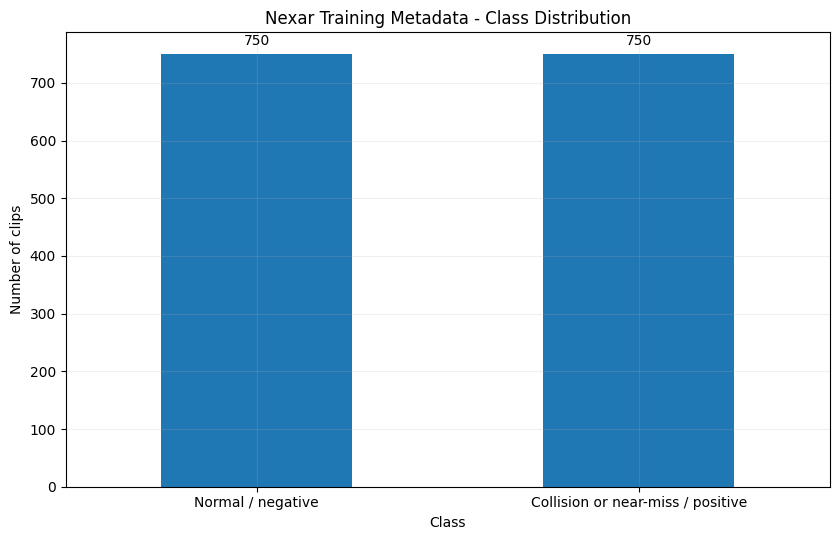

Saved: /content/roadrisk_nexar_figures/fig_04_nexar_class_distribution.png


In [4]:
if label_col is None:
    print('No usable label column found. Skip this figure and inspect the columns above.')
else:
    counts=work[label_col].value_counts(dropna=False).sort_index()
    # Map the common binary values to readable names while preserving unknown values.
    labels=[]
    for idx in counts.index:
        if str(idx) in ['0','0.0','False']:
            labels.append('Normal / negative')
        elif str(idx) in ['1','1.0','True']:
            labels.append('Collision or near-miss / positive')
        else:
            labels.append(str(idx))
    ax=pd.Series(counts.values,index=labels).plot(kind='bar')
    ax.set_title('Nexar Training Metadata - Class Distribution')
    ax.set_xlabel('Class')
    ax.set_ylabel('Number of clips')
    ax.tick_params(axis='x',rotation=0)
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height()):,}',(p.get_x()+p.get_width()/2,p.get_height()),
                    ha='center',va='bottom',xytext=(0,4),textcoords='offset points')
    plt.tight_layout()
    path=os.path.join(OUTPUT_DIR,'fig_04_nexar_class_distribution.png')
    plt.savefig(path,dpi=220,bbox_inches='tight')
    plt.show()
    print('Saved:',path)


### Figure 5 - Alert lead-time distribution

For positive cases with both timestamps:

\[
LeadTime = Time_{event} - Time_{alert}
\]

This is useful for discussing how much warning time exists in the annotations. It is **not** evidence that your own model already achieves that warning time.

count    750.000000
mean       1.600357
std        0.866063
min        0.033000
25%        0.986250
50%        1.433000
75%        2.089500
90%        2.867000
max        4.466000
Name: lead_time_seconds, dtype: float64


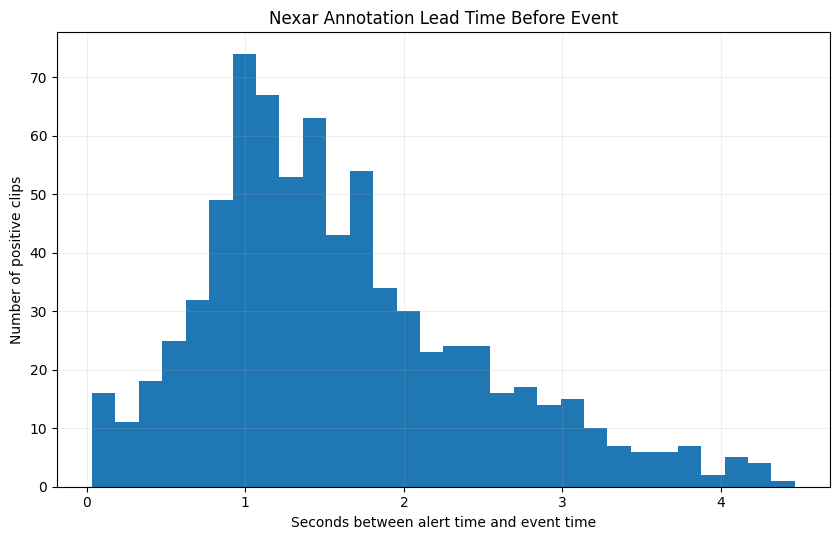

Saved: /content/roadrisk_nexar_figures/fig_05_nexar_alert_lead_time.png


In [5]:
required={'time_of_event','time_of_alert'}
if required.issubset(work.columns):
    tmp=work.copy()
    tmp['time_of_event']=pd.to_numeric(tmp['time_of_event'],errors='coerce')
    tmp['time_of_alert']=pd.to_numeric(tmp['time_of_alert'],errors='coerce')
    tmp['lead_time_seconds']=tmp['time_of_event']-tmp['time_of_alert']
    lead=tmp['lead_time_seconds'].dropna()
    lead=lead[lead>=0]

    print(lead.describe(percentiles=[0.25,0.5,0.75,0.9]))
    ax=lead.plot(kind='hist',bins=30)
    ax.set_title('Nexar Annotation Lead Time Before Event')
    ax.set_xlabel('Seconds between alert time and event time')
    ax.set_ylabel('Number of positive clips')
    plt.tight_layout()
    path=os.path.join(OUTPUT_DIR,'fig_05_nexar_alert_lead_time.png')
    plt.savefig(path,dpi=220,bbox_inches='tight')
    plt.show()
    print('Saved:',path)
else:
    print('time_of_event/time_of_alert columns not found; skip this figure.')


### Figure 6 - Scene, weather and light-condition distributions (when available)

The Hugging Face dataset view includes these fields, while some Kaggle CSV copies may not. The code automatically plots only columns that exist.

In [6]:
categorical_candidates=['scene','weather','light_conditions']
for col in categorical_candidates:
    if col not in work.columns:
        print(f'Skipping {col}: column not present.')
        continue
    vc=work[col].fillna('Unknown').astype(str).value_counts()
    ax=vc.sort_values().plot(kind='barh',figsize=(8.5,max(4,0.45*len(vc))))
    ax.set_title(f'Nexar Metadata - {col.replace("_"," ").title()}')
    ax.set_xlabel('Number of clips')
    ax.set_ylabel(col.replace('_',' ').title())
    plt.tight_layout()
    path=os.path.join(OUTPUT_DIR,f'fig_06_{col}.png')
    plt.savefig(path,dpi=220,bbox_inches='tight')
    plt.show()
    print('Saved:',path)


Skipping scene: column not present.
Skipping weather: column not present.
Skipping light_conditions: column not present.


## 3. Proposal-ready numerical summary

In [7]:
summary={
    'rows':len(work),
    'columns':len(work.columns),
}
if label_col:
    vc=work[label_col].value_counts()
    summary['positive_rows']=int(vc.get(1,vc.get('1',0)))
    summary['negative_rows']=int(vc.get(0,vc.get('0',0)))
if {'time_of_event','time_of_alert'}.issubset(work.columns):
    e=pd.to_numeric(work['time_of_event'],errors='coerce')
    a=pd.to_numeric(work['time_of_alert'],errors='coerce')
    lead=(e-a).dropna()
    lead=lead[lead>=0]
    if len(lead):
        summary['lead_time_median_s']=float(lead.median())
        summary['lead_time_mean_s']=float(lead.mean())
        summary['lead_time_p90_s']=float(lead.quantile(.90))

summary_df=pd.DataFrame([summary])
display(summary_df)
summary_df.to_csv('/content/nexar_metadata_summary.csv',index=False)


,rows,columns,positive_rows,negative_rows,lead_time_median_s,lead_time_mean_s,lead_time_p90_s
0,1500,4,750,750,1.433,1.600357,2.867


## 4. Export figures

In [8]:
zip_path='/content/roadrisk_nexar_figures.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for fname in sorted(os.listdir(OUTPUT_DIR)):
        z.write(os.path.join(OUTPUT_DIR,fname),arcname=fname)
    if os.path.exists('/content/nexar_metadata_summary.csv'):
        z.write('/content/nexar_metadata_summary.csv',arcname='nexar_metadata_summary.csv')
print('Created:',zip_path)
files.download(zip_path)


Created: /content/roadrisk_nexar_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to interpret these results in the report

- **Class distribution:** establishes that there is a labelled benchmark for normal versus collision/near-miss events.
- **Lead time:** explains the dataset's early-warning annotation design; do not present it as your model performance.
- **Scene/weather/light:** helps identify domain coverage and missing Sri Lankan conditions.
- **Next step:** only after this descriptive analysis, run a small pretrained inference baseline on video. Fine-tune only if the baseline fails on the target traffic conditions.
